1. Load ENV Variable 

In [1]:
import os 
from getpass import getpass
try:
    from dotenv import load_dotenv
    load_dotenv()
except Exception as e:
    print(f"Error loading .env file: {e}")

if not os.getenv("GROQ_API_KEY"):
    os.environ["GROQ_API_KEY"] = getpass("Enter your GROQ API Key: ")

if not os.getenv("TAVILY_API_KEY"):
    os.environ["TAVILY_API_KEY"] = getpass("Enter your TAVILY API Key: ")

if not os.getenv("PINECONE_API_KEY"):
    os.environ["PINECONE_API_KEY"] = getpass("Enter your PINECONE API Key: ")

print("GROQ API Key:",bool(os.getenv("GROQ_API_KEY")))
print("TAVILY API Key:",bool(os.getenv("TAVILY_API_KEY")))
print("PINECONE API Key:",bool(os.getenv("PINECONE_API_KEY")))




GROQ API Key: True
TAVILY API Key: True
PINECONE API Key: True


2. LOAD DOCUMENTS 

In [2]:
from langchain_community.document_loaders import WebBaseLoader

SOURCE_URL = "https://docs.langchain.com/oss/python/langgraph/agentic-rag"

loader = WebBaseLoader(
    web_paths=(SOURCE_URL,),
    requests_kwargs={
        "headers": {
            "User-Agent": "Mozilla/5.0 Agentic-RAG-Industry-Demo"
            
        }
    },
)

raw_docs = loader.load()

print("Loaded documents:", len(raw_docs))
print("Source:", raw_docs[0].metadata.get("source"))
print("\nPreview:\n")
print(raw_docs[0].page_content[:1500].encode("utf-8", errors="replace").decode("utf-8"))


C:\Users\Aman\AppData\Local\Temp\ipykernel_12784\1504425881.py:1: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
c:\Users\Aman\Desktop\RAG\venv312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
USER_AGENT environment variable not set, consider setting it to identify your requests.


Loaded documents: 1
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag

Preview:

Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandoffs: Customer supportRouter: Knowledge baseSkills: SQL assistantLangGraphCustom RAG agentCustom SQL agentConceptual overviewsLangChain vs. LangGraph vs. Deep AgentsProviders and modelsComponent architectureMemoryContextHuman-in-the-loopGraph APIFunctional AP

3. SPILTING THE DOCUMENT INTO CHUNKS 

In [3]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

spiltter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=150,
    add_start_index=True
)

chunks = spiltter.split_documents(raw_docs)

print("Split into chunks:", len(chunks))
print("Preview of first chunk:\n")
print(chunks[0].page_content[:1000])


Split into chunks: 28
Preview of first chunk:

Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandoffs: Customer supportRouter: Knowledge baseSkills: SQL assistantLangGraphCustom RAG agentCustom SQL agentConceptual overviewsLangChain vs. LangGraph vs. Deep AgentsProviders and modelsComponent architectureMemoryContextHuman-in-the-loopGraph APIFunctional APIAdditional resourcesUse docs programmaticallyLangCh

4. LOCAL EMBEDDINGS

In [4]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    encode_kwargs={"normalize_embeddings": True}
)
sample_embedding = embeddings.embed_query("What is Agentic RAG?")
print("Embedding dimensions:", len(sample_embedding))


Loading weights: 100%|██████████| 103/103 [00:00<00:00, 51509.87it/s]


Embedding dimensions: 384


5. CREATING PINECONE VECTOR DATABASE 

In [5]:
from pinecone import Pinecone, ServerlessSpec
from langchain_pinecone import PineconeVectorStore
import time

INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag"

# Connect to Pinecone
pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

# Create the index only if it does not already exist.
existing_indexes = [index_info["name"] for index_info in pc.list_indexes()]

if INDEX_NAME not in existing_indexes:
    pc.create_index(
        name=INDEX_NAME,
        dimension=384,       # all-MiniLM-L6-v2 embedding dimension
        metric="cosine",
        spec=ServerlessSpec(
            cloud="aws",
            region="us-east-1",
        ),
    )

    # Wait until Pinecone reports the new index as ready.
    while not pc.describe_index(INDEX_NAME).status["ready"]:
        time.sleep(1)

print("Pinecone index ready:", INDEX_NAME)

# Upload the document chunks and create the LangChain vector store.
vectorstore = PineconeVectorStore.from_documents(
    documents=chunks,
    embedding=embeddings,
    index_name=INDEX_NAME,
    namespace=NAMESPACE,
)

retriever = vectorstore.as_retriever(
    search_kwargs={
        "k": 4,
        "namespace": NAMESPACE,
    }
)

print("Pinecone vector database and retriever are ready.")


Pinecone index ready: industry-agentic-rag-kb
Pinecone vector database and retriever are ready.


In [6]:
from pinecone import Pinecone
from langchain_pinecone import PineconeVectorStore

INDEX_NAME = "industry-agentic-rag-kb"
NAMESPACE = "langgraph-agentic-rag"

# Connect to Pinecone
pc = Pinecone(api_key=os.environ["PINECONE_API_KEY"])

# Load existing Pinecone index
index = pc.Index(INDEX_NAME)

# Connect existing index with LangChain
vectorstore = PineconeVectorStore(
    index=index,
    embedding=embeddings,
    namespace=NAMESPACE,
)

# Create retriever
retriever = vectorstore.as_retriever(
    search_kwargs={
        "k": 4,
        "namespace": NAMESPACE,
    }
)

print("Existing Pinecone index loaded:", INDEX_NAME)


Existing Pinecone index loaded: industry-agentic-rag-kb


6. TEST KB


In [7]:
test_question = "What happens if retrieved documents are not relevant in Agentic RAG?"

kb_docs = retriever.invoke(test_question)

for i, doc in enumerate(kb_docs, 1):
    print(f"\n--- KB RESULT {i} ---")
    print("Source:", doc.metadata.get("source"))
    print(doc.page_content[:700])



--- KB RESULT 1 ---
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: /llms.txtUse this file to discover all available pages before exploring further.Skip to main contentDocs by LangChain home pageBuildSearch...⌘KAsk AIGitHubTry LangSmithTry LangSmithSearch...NavigationLangGraphBuild a custom RAG agent with LangGraphOverviewDeep AgentsManaged Deep AgentsLangChainLangGraphOpenWikiIntegrationsLearnReferenceContributePythonLearnTutorialsDeep AgentsData AnalysisDeep ResearchContent BuilderRAGLangChainDeep AgentSemantic searchSQL agentVoice agentMulti-agentSubagents: Personal assistantHandoffs: Customer supportRouter: Knowledge baseSkills: SQL as

--- KB RESULT 2 ---
Source: https://docs.langchain.com/oss/python/langgraph/agentic-rag
Build a custom RAG agent with LangGraph - Docs by LangChainDocumentation IndexFetch the complete documentation index at: 

7. initialize Groq LLM

In [8]:
from langchain_groq import ChatGroq

llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
)

print (llm.invoke("What is Agentic RAG?").content)


## Agentic Retrieval‑Augmented Generation (Agentic RAG)

**Agentic RAG** is a recent design pattern for large‑language‑model (LLM) agents that combines the classic *Retrieval‑Augmented Generation* (RAG) pipeline with *agentic* (autonomous, goal‑driven) capabilities.  
In short: it is a RAG system that can *plan*, *act*, and *refine* its own queries and responses, rather than simply retrieving a static set of documents and generating a single answer.

---

### 1. Quick recap: What is RAG?

| Step | What happens | Typical tools |
|------|--------------|---------------|
| **Retrieval** | The model (or a separate retriever) fetches relevant documents from a knowledge base (vector store, search engine, etc.) based on the user query. | BM25, FAISS, Pinecone, ElasticSearch, etc. |
| **Augmentation** | The retrieved passages are concatenated (or otherwise fed) into the prompt for the LLM. | Prompt templates, chain‑of‑thought prompts, etc. |
| **Generation** | The LLM produces an answer that is

8. Init Tavily web search

In [9]:

from langchain_tavily import TavilySearch

web_search = TavilySearch(
    max_results=5,
    topic="general",
    include_answer=True,
    include_raw_content=False,
)

print("Tavily search tool ready.")


Tavily search tool ready.


9. define structure decisions


In [10]:
from typing import List, Literal,Optional
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langchain_core.documents import Document

class RouteDecision(BaseModel):
    route:Literal["kb","direct"]=Field(
        description="use kb for questions needing agentic RAG docs ;direct for greeting/simple chat."
    )
class EvidenceGrade(BaseModel):
    grade:Literal["good","weak"]=Field(
        description="good means evidence can answer the question ; weak means not enough evidence to answer the question"
    )

class AgentState(TypedDict):
    question:str
    current_query:str
    kb_docs:List[Document]
    web_results:str
    kb_grade:str
    web_grade:str
    answer:str
    source_used:str
    retry_count:int


10. Node 1 - Route the Questions

In [11]:
router_llm = llm.with_structured_output(RouteDecision, method="json_mode")

def route_question(state:AgentState):
    question=state["question"]
    decision=router_llm.invoke(f'''
You are a router for an Agentic RAG assistant.

Route to "kb" if the user asks about:
- Agentic RAG
- LangGraph Agentic RAG workflow
- retrieval grading
- query rewriting
- RAG architecture
- retriever tools
- web fallback in RAG

Route to "direct" only for greetings, thanks, or very simple conversation.

Question:
{question}

Return your response as valid JSON.
Example:
{{"route": "kb"}}
''')
    print ("[ROUTER DECISION]",decision.route)
    return{
        "current_query":question,
        "source_used":decision.route,
    }

def route_after_router(state:AgentState)->Literal["retrieve_kb","direct_answer"]:
    if state["source_used"]=="kb":
        return "retrieve_kb"
    else:
        return "direct_answer"



11. node 2 Retrieve from private KB

In [12]:
def retrieve_kb(state:AgentState):
    query=state["current_query"]
    docs=retriever.invoke(query)

    print(f"[KB RETRIEVER] QUERY : {query}")
    print(f"[KB RETRIEVER] Retrieved {len(docs)} chunks.")

    return {
        "kb_docs":docs,}


12. node 3 Grade KB evidence 

In [13]:
kb_grade_llm=llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_kb_evidence(state:AgentState):
    question=state["question"]
    context="\n\n".join(
        f"Source:{doc.metadata.get('source')}\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    grade=kb_grade_llm.invoke(f'''
You are an evidence grader for an Agentic RAG assistant.

Question: {question}

Private kB evidence: {context}

can this private KB evidence answer the question?
return "good" if it can answer the question, or "weak" if it cannot answer the question.

Return your response as valid JSON.
Example:
{{"grade": "good"}}
''')
    print ("[KB GRADE]",grade.grade)
    return {
        "kb_grade":grade.grade,
    }
def decide_after_kb_grade(state:AgentState)->Literal["generate_from_kb","search_web"]:
    if state["kb_grade"]=="good":
        return "generate_from_kb"
    else:
        return "search_web"


13. node 4 - Tavily web search Fallback

In [14]:
def search_web(state:AgentState):
    query=state["current_query"]

    print (f"[Tavily Search] Searching web for query: {query}")
    results=web_search.invoke({"query": query})

    if isinstance(results, dict):
        answer=results.get("answer", "")
        result=results.get("results", [])
        lines=[]
        if answer:
            lines.append(f" tavily Answer: {answer}")
        for item in result:
            title=item.get("title","")
            url=item.get("url","")
            content=item.get("content","")
            lines.append(f"Title: {title}\nURL: {url}\nContent: {content}\n")
        web_text="\n".join(lines) if lines else str(results)
    else:
        web_text=str(results)
    print(f"[TavilySearch]  results characters: {len(web_text)}")

    return {
        "web_results":web_text,
        "source_used":"web",
    }


14. Node 5 Grade WEB evidence 

In [15]:
web_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_web_evidence(state: AgentState):
    question = state["question"]
    web_results = state["web_results"]

    grade = web_grader_llm.invoke(f'''
You are an evidence grader.

Question:
{question}

Web search evidence:
{web_results}

Can this web evidence answer the question?
Return "good" if it can answer.
Return "weak" if it cannot answer or is incomplete.

Return your response as valid JSON.
Example:
{{"grade": "good"}}
''')

    print("[Web Grader]", grade.grade)

    return {"web_grade": grade.grade}


MAX_RETRIES = 1

def decide_after_web_grade(state: AgentState) -> Literal["generate_from_web", "rewrite_query", "answer_insufficient"]:
    if state["web_grade"] == "good":
        return "generate_from_web"

    if state["retry_count"] < MAX_RETRIES:
        return "rewrite_query"

    return "answer_insufficient"  # fallback to web generation even if weak


15. NODE 6 Rewrite the query

In [16]:
from langchain_core.messages import HumanMessage

def rewrite_query(state: AgentState):
    question = state["question"]
    retry_count = state["retry_count"]+1

    rewritten=llm.invoke(f'''Rewrite the question for better retrieval and web search.

Rules:
- Preserve original intent.
- Make it specific and search-friendly.
- Do not answer.
- Return only the rewritten query.

Original question:
{question}
''').content.strip()

    print(f"[Query Rewriter] Rewritten query: {rewritten}")

    return {
        "current_query": rewritten, 
        "retry_count": retry_count,
    }


node 7 Generate from Private KB

In [17]:
def generate_from_kb(state: AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"[KB Source: {doc.metadata.get('source')}]\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    answer = llm.invoke(f'''
You are a technical instructor.

Answer using ONLY the private KB context.

Rules:
- Beginner-friendly explanation.
- Do not invent unsupported details.
- Mention that the answer is based on the private KB.
- Include source type: Private KB.

Question:
{question}

Private KB context:
{context}
''').content

    return {
        "answer": answer,
        "source_used": "private_kb",
    }


16. node 8 Generate from web search 

In [18]:
def generate_from_web(state:AgentState):
    question=state["question"]
    web_context=state["web_results"]

    answer=llm.invoke(f'''
You are a technical instructor.

The private KB was insufficient, so web search was used.

Answer using ONLY the web search context.

Rules:
- Beginner-friendly explanation.
- Do not invent unsupported details.

Question:
{question}

Web search context:
{web_context}
''').content.strip()

    # Extract URLs from web context
    import re
    urls = re.findall(r'URL: (https?://[^\s]+)', web_context)
    unique_urls = list(dict.fromkeys(urls))[:4]

    # Build structured metadata
    metadata_parts = []
    if "based on Tavily web search" not in answer.lower():
        metadata_parts.append("*Answer based on Tavily web search.*")

    metadata_parts.append("**Source type:** Web Search")

    if unique_urls:
        metadata_parts.append("")
        metadata_parts.append("**Useful URLs**")
        for url in unique_urls:
            metadata_parts.append(f"- {url}")

    formatted_answer = answer + "\n\n" + "\n".join(metadata_parts)

    return {
        "answer": formatted_answer,
        "source_used": "web_search",
    }


18. Node 9 Direct Answer

In [19]:
def direct_answer(state:AgentState):
    question=state["question"]

    answer=llm.invoke(f'''
Respond briefly and naturally.

Message:
{question}
''').content
    
    return {
        "answer": answer,
        "source_used": "direct",
    }




19. Insufficient Evidence Answer

In [20]:
def answer_insufficient(state:AgentState):
    answer=(
        "I could not find enough reliable evidence in the private knowledge base "
        "or the web search results to answer this confidently. "
        "Please provide more specific documents or rephrase the question."
    )
    return {
        "answer": answer,
        "source_used": "insufficient_evidence",
    }



20. Build the LangGraph Workflow

In [ ]:
from langgraph.graph import StateGraph, START,END
workflow = StateGraph(AgentState)

workflow.add_node("route_question", route_question)
workflow.add_node("retrieve_kb", retrieve_kb)
workflow.add_node("grade_kb_evidence", grade_kb_evidence)
workflow.add_node("search_web", search_web)
workflow.add_node("grade_web_evidence", grade_web_evidence)
workflow.add_node("rewrite_query", rewrite_query)
workflow.add_node("generate_from_kb", generate_from_kb)
workflow.add_node("generate_from_web", generate_from_web)
workflow.add_node("direct_answer", direct_answer)
workflow.add_node("answer_insufficient", answer_insufficient)

workflow.add_edge(START, "route_question")
workflow.add_conditional_edges(
    "route_question",
    route_after_router,{
        "retrieve_kb": "retrieve_kb",
        "direct_answer": "direct_answer",
    },

)
workflow.add_edge("retrieve_kb", "grade_kb_evidence")
workflow.add_conditional_edges(
    "grade_kb_evidence",
    decide_after_kb_grade,{
        "generate_from_kb": "generate_from_kb",
        "search_web": "search_web",
    },
)
workflow.add_edge("search_web", "grade_web_evidence")
workflow.add_conditional_edges(
    "grade_web_evidence",
    decide_after_web_grade,{
        "generate_from_web": "generate_from_web",
        "rewrite_query": "rewrite_query",
        "answer_insufficient": "answer_insufficient",
    },
)

workflow.add_edge("rewrite_query", "retrieve_kb")  # Retry retrieval after rewriting the query
workflow.add_edge("generate_from_kb", END)
workflow.add_edge("generate_from_web", END)
workflow.add_edge("direct_answer", END)
workflow.add_edge("answer_insufficient", END)

app=workflow.compile()

print("Agentic RAG workflow compiled and ready.")


Agentic RAG workflow compiled and ready.


Visualize the Graph

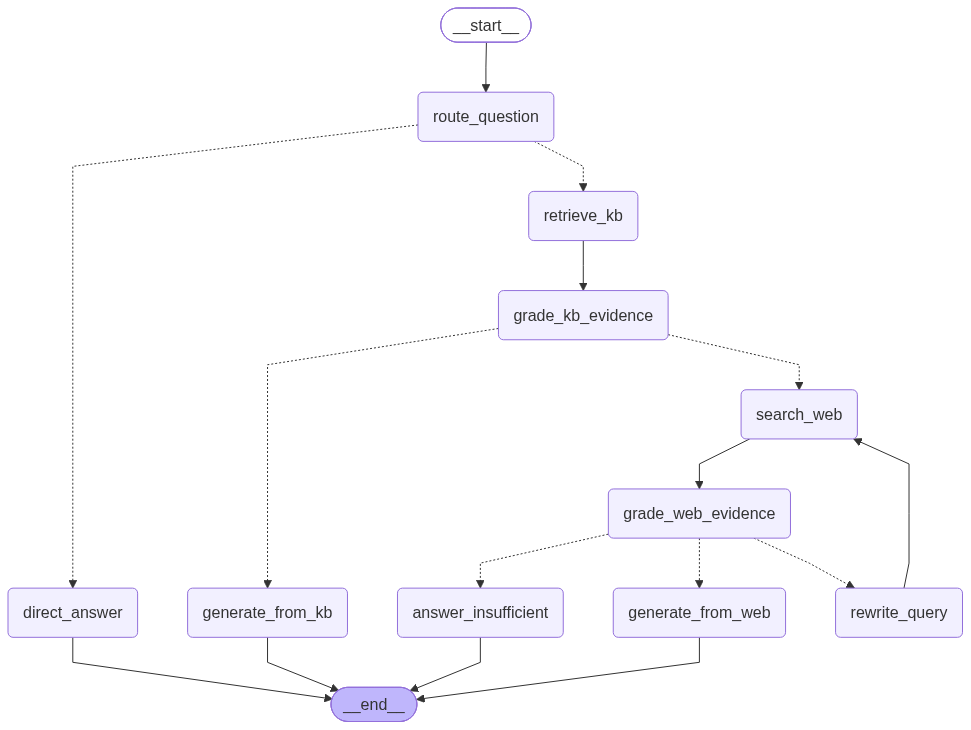

In [22]:
from IPython.display import display,Image

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print(f"Error displaying graph: {e}")


Helper Function

In [23]:
def ask_agent(question:str):
    initial_state :AgentState = {
        "question": question,
        "current_query": question,
        "kb_docs": [],
        "web_results": "",
        "kb_grade": "",
        "web_grade": "",
        "answer": "",
        "source_used": "",
        "retry_count": 0,
    }

    result = app.invoke(initial_state)

    print("\n" + "=" * 90)
    print("QUESTION:")
    print(question)
    print("\nSOURCE USED:")
    print(result["source_used"])
    print("\nFINAL ANSWER:")
    print(result["answer"])
    print("=" * 90)

    return result


DEMO 1 QUESTION FROM PRIVATE KB

In [24]:
result =ask_agent("What is Agentic RAG and how does it work?")


[ROUTER DECISION] kb
[KB RETRIEVER] QUERY : What is Agentic RAG and how does it work?
[KB RETRIEVER] Retrieved 4 chunks.
[KB GRADE] weak
[Tavily Search] Searching web for query: What is Agentic RAG and how does it work?
[TavilySearch]  results characters: 6579
[Web Grader] good

QUESTION:
What is Agentic RAG and how does it work?

SOURCE USED:
web_search

FINAL ANSWER:
**Agentic RAG** is a newer way of building AI chat‑bots and assistants that combine two ideas:

1. **Retrieval‑Augmented Generation (RAG)** – a system that asks a large language model (LLM) to fetch documents or facts from a database, then uses those documents to write an answer.  
2. **AI agents** – small, autonomous “helpers” that can plan, decide what to do next, and call tools or other agents.

---

### How it works (step‑by‑step)

| Step | What happens | Why it matters |
|------|--------------|----------------|
| **1. User asks a question** | The user’s prompt is sent to the system. | The system starts with a real p

QUESTION 2 

In [25]:

result = ask_agent(
    "What is Tavily Search and why is it useful for AI agents and RAG workflows?"
)


[ROUTER DECISION] kb
[KB RETRIEVER] QUERY : What is Tavily Search and why is it useful for AI agents and RAG workflows?
[KB RETRIEVER] Retrieved 4 chunks.
[KB GRADE] weak
[Tavily Search] Searching web for query: What is Tavily Search and why is it useful for AI agents and RAG workflows?
[TavilySearch]  results characters: 7669
[Web Grader] good

QUESTION:
What is Tavily Search and why is it useful for AI agents and RAG workflows?

SOURCE USED:
web_search

FINAL ANSWER:
**What is Tavily Search?**  
Tavily Search is a web‑search API that was built from the ground up for artificial‑intelligence (AI) agents and for *retrieval‑augmented generation* (RAG) pipelines.  
* It lets an AI system ask a question, pull in fresh information from the live web, and then use that information to answer or act.  
* Instead of giving a list of links for a human to click, Tavily returns short, AI‑friendly snippets that are already ranked and cleaned.  
* The API also offers extra features such as extracting